# Customer Journey, Conversion & Experimentation Analytics

I used REES46 events to examine conversion measurement and purchase journeys, then analyzed the separate Hillstrom email experiment. The two datasets have different customers and periods.

Run the cells in order. The Power BI report and decision memo are linked in README.


---

## Analysis section: Eda


## Event data

The REES46 section queries the retained events in a read-only SQLite model. SQL queries are in `analysis.sql (section 06_eda_queries.sql)`. Record counts and customer counts measure different things.


In [1]:
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

from pathlib import Path
import sqlite3, sys
root = globals().get("PROJECT_ROOT", Path.cwd())
if not (root / "src/run_eda.py").exists():
    root = root.parent
assert (root / "src/run_eda.py").exists(), "Open from the project or notebooks directory"
sys.path.insert(0, str(root / "src"))
from run_eda import collect, verify, render_figures
with sqlite3.connect((root / "data/processed/project01.sqlite").as_uri() + "?mode=ro", uri=True) as conn:
    profiles = collect(conn)
print(verify(profiles))
print(profiles["model_counts"])

# Recreate the Markdown figures from the checked aggregates in this run.
render_figures(profiles, root / "images");


{'all_event_profiles_reconcile': True, 'all_purchase_profiles_reconcile': True, 'user_session_product_buckets_reconcile': True, 'price_population_reconciles': True}
{'fact_event': 884474, 'dim_user': 407283, 'dim_product': 53453, 'fact_session_30': 504679}
Out[1]: 
[PosixPath('images/eda_time.png'),
 PosixPath('images/eda_behavior.png')]


### Event composition

`COUNT(*)` counts events; `COUNT(DISTINCT user_id)` counts observed customer IDs. Event shares are not an ordered conversion funnel.


In [2]:
for row in profiles["event_mix"]:
    print(row)


{'event_type': 'cart', 'events': 54032, 'users_with_event': 36952}
{'event_type': 'purchase', 'events': 37343, 'users_with_event': 21304}
{'event_type': 'view', 'events': 793099, 'users_with_event': 406863}


## 2. Time exposure

All timestamps are UTC. September has only seven represented dates. For complete calendar months, compare events per represented date. This does not establish uninterrupted logging or the cause of volume changes.


In [3]:
for row in profiles["monthly_utc"]:
    print(row["month"], "dates:", row["represented_dates"], "events/date:", round(row["events_per_represented_date"], 2), "partial:", row["partial_calendar_month"])


2020-09 dates: 7 events/date: 4008.43 partial: True
2020-10 dates: 31 events/date: 5207.03 partial: False
2020-11 dates: 30 events/date: 6269.7 partial: False
2020-12 dates: 31 events/date: 4922.26 partial: False
2021-01 dates: 31 events/date: 6046.48 partial: False
2021-02 dates: 28 events/date: 5959.82 partial: False


![Event volume over time](images/eda_time.png)


## 3. Recorded behavior, prices and product concentration

Single-event users are not automatically bounces. First-to-last event span is not active time. Prices are event-weighted source units, not average order value. Top-product coverage describes recorded events, not sales or exposure-adjusted popularity.


In [4]:
for key in ["user_event_frequency", "session_event_frequency", "price_summary", "product_concentration", "attribute_missingness"]:
    print(key)
    print(profiles[key])


user_event_frequency
[{'event_count_bucket': '1', 'users': 266473, 'events': 266473, 'max_user_events': 1}, {'event_count_bucket': '2-3', 'users': 92601, 'events': 214071, 'max_user_events': 3}, {'event_count_bucket': '4-9', 'users': 38227, 'events': 206237, 'max_user_events': 9}, {'event_count_bucket': '10+', 'users': 9982, 'events': 197693, 'max_user_events': 572}]
session_event_frequency
[{'event_count_bucket': '1', 'sessions': 353734, 'events': 353734, 'single_timestamp_sessions': 353734}, {'event_count_bucket': '2-3', 'sessions': 106961, 'events': 247046, 'single_timestamp_sessions': 551}, {'event_count_bucket': '4-9', 'sessions': 38636, 'events': 202240, 'single_timestamp_sessions': 18}, {'event_count_bucket': '10+', 'sessions': 5348, 'events': 81454, 'single_timestamp_sessions': 0}]
price_summary
{'weighting': 'event-weighted, all retained event types', 'units': 'source-reported price units; currency not assumed', 'count': 884474, 'minimum': 0.22, 'median': 65.71, 'p95': 486.81,

![Behavior and recorded prices](images/eda_behavior.png)

The next section applies the frozen denominators to segment comparisons. Missing categories and brands remain in the population.


---

## Analysis section: Conversion Diagnostics


## Purchase journeys

This section checks the frozen measurement definitions against the model, then compares categories and first-view price bands. Purchase events are not verified orders. These observational records do not identify causes, and they are not joined to Hillstrom.


### Open the model

The connection is read-only. I check the model and raw-file hashes before querying them. pandas holds query results; SQLite performs the grouping and joins.


In [5]:
from pathlib import Path
import json, sqlite3, sys, os
import pandas as pd

root = Path.cwd()
if not (root / "data/processed/project01.sqlite").exists():
    root = root.parent
assert (root / "data/processed/project01.sqlite").exists()
sys.path.insert(0, str(root / "src"))
from intake import file_hash

os.environ.setdefault("MPLCONFIGDIR", str(root / "data/work/mpl-cache"))
model = root / "data/processed/project01.sqlite"
before_model = file_hash(model)
expected = json.loads((root / "reports/05_model_validation.json").read_text())["model_sha256"]
assert before_model == expected
raw_paths = [root / "data/raw/rees46/events.csv", root / "data/raw/hillstrom/hillstrom.csv.gz"]
before_raw = {str(path): file_hash(path) for path in raw_paths}
conn = sqlite3.connect(model.as_uri() + "?mode=ro", uri=True)
conn.execute("PRAGMA temp_store=MEMORY")
print("Read-only model opened; source/model fingerprints recorded.")


Read-only model opened; source/model fingerprints recorded.


### Customer and session purchase shares

U01 measures purchasing observed customer IDs. S01 measures sessions containing a purchase. Their denominators differ, so they cannot be presented as successive funnel stages.


In [6]:

from intake import read_sql
snapshot = pd.read_sql_query(read_sql('05_metric_queries.sql'), conn).iloc[0]
snapshot_rates = pd.DataFrame([
    {"metric": "U01: observed users", "numerator": snapshot["user_num"], "denominator": snapshot["user_den"]},
    {"metric": "S01: observed 30-minute sessions", "numerator": snapshot["session_num"], "denominator": snapshot["session_den"]}
])
snapshot_rates["percent"] = 100 * snapshot_rates["numerator"] / snapshot_rates["denominator"]
display(snapshot_rates.round(3))


,metric,numerator,denominator,percent
0,U01: observed users,21304,407283,5.231
1,S01: observed 30-minute sessions,24506,504679,4.856


### Define eligible journeys and first-view attributes

`session_30` is a customer-session-product group with an observed view and a complete session-close buffer. `pair_7d` is a customer-product pair with seven full days after its first view.

Both require strict view < cart < purchase timestamps. Category and price come from the first view, not a later purchase. The earliest source row breaks an attribute tie at the same timestamp; it does not establish behavioral order. `analysis.sql (section 07_diagnostic_cohorts.sql)` creates temporary tables without changing the saved model.


In [7]:

from intake import read_sql
setup_sql = read_sql('07_diagnostic_cohorts.sql')
conn.executescript(setup_sql)
print("Temporary eligible groups created using first-view attributes.")


Temporary eligible groups created using first-view attributes.


### Count stages and calculate rates

Each eligible group contributes one row. Summing `cart_reached` and `ordered_purchase_reached` counts groups that reached each stage. Cart-to-purchase uses reached-cart groups as its denominator, rather than all eligible views.


In [8]:
overall = pd.read_sql_query("""
SELECT cohort, COUNT(*) AS eligible_groups,
       SUM(cart_reached) AS cart_groups,
       SUM(ordered_purchase_reached) AS ordered_purchase_groups,
       COUNT(DISTINCT user_id) AS distinct_users
FROM diagnostic_view_groups
GROUP BY cohort
ORDER BY cohort
""", conn)

def add_rates(frame):
    frame = frame.copy()
    frame["view_to_cart_pct"] = 100 * frame["cart_groups"] / frame["eligible_groups"]
    frame["ordered_purchase_pct"] = 100 * frame["ordered_purchase_groups"] / frame["eligible_groups"]
    cart_den = frame["cart_groups"].where(frame["cart_groups"] != 0)
    frame["cart_to_ordered_purchase_pct"] = 100 * frame["ordered_purchase_groups"] / cart_den
    return frame

overall = add_rates(overall)
display(overall.round(3))


,cohort,eligible_groups,cart_groups,ordered_purchase_groups,distinct_users,view_to_cart_pct,ordered_purchase_pct,cart_to_ordered_purchase_pct
0,pair_7d,532888,42526,21246,390530,7.980,3.987,49.960
1,session_30,644660,49459,23672,406842,7.672,3.672,47.862


### Reconcile the stage counts

Assertions compare the computed numerators and denominators with the saved baseline. A mismatch stops execution before the segment comparisons.


In [9]:
expected_counts = {
    "session_30": [snapshot["session_product_den"], snapshot["session_product_cart_num"], snapshot["session_product_purchase_num"]],
    "pair_7d": [snapshot["view7_den"], snapshot["view_cart7_num"], snapshot["view_cart_purchase7_num"]]
}
count_columns = ["eligible_groups", "cart_groups", "ordered_purchase_groups"]
for _, row in overall.iterrows():
    assert row[count_columns].tolist() == expected_counts[row["cohort"]]
primary = overall.loc[overall["cohort"] == "session_30"].iloc[0]
print("Both cohorts match the Chapter 05 contracted counts.")


Both cohorts match the Chapter 05 contracted counts.


### Compare categories

The chart shows the ten largest eligible denominators, not categories selected for favorable rates. Unknown remains in the analysis. Customers can occur in multiple categories and sessions; distinct-customer counts are not additive.

The display rule requires 1,000 eligible groups, 500 customer IDs, 100 cart groups and 30 ordered-purchase groups. It describes support, not statistical significance or independence.


In [10]:
categories = pd.read_sql_query("""
SELECT category_label, category_missing, COUNT(*) AS eligible_groups,
       SUM(cart_reached) AS cart_groups,
       SUM(ordered_purchase_reached) AS ordered_purchase_groups,
       COUNT(DISTINCT user_id) AS distinct_users
FROM diagnostic_view_groups
WHERE cohort = 'session_30'
GROUP BY category_label, category_missing
ORDER BY eligible_groups DESC, category_label
""", conn)
categories = add_rates(categories)
thresholds = json.loads((root / "docs/07_diagnostic_plan.json").read_text())["presentation_support_thresholds"]
categories["below_presentation_threshold"] = False
for column, minimum in thresholds.items():
    categories["below_presentation_threshold"] |= categories[column] < minimum
for column in count_columns:
    assert categories[column].sum() == primary[column]
saved_categories = pd.read_csv(root / "reports/07_category.csv")
saved_categories = saved_categories.loc[saved_categories["cohort"] == "session_30"]
pd.testing.assert_frame_equal(
    categories.set_index(["category_label", "category_missing"])[count_columns].sort_index(),
    saved_categories.set_index(["category_label", "category_missing"])[count_columns].sort_index(),
    check_dtype=False
)
display(categories.head(10).round(3))


,category_label,category_missing,eligible_groups,cart_groups,ordered_purchase_groups,distinct_users,view_to_cart_pct,ordered_purchase_pct,cart_to_ordered_purchase_pct,below_presentation_threshold
0,Unknown,1,180978,9472,4778,129893,5.234,2.640,50.443,False
1,computers.components.videocards,0,72098,11698,4712,29029,16.225,6.536,40.280,False
2,electronics.telephone,0,61107,4930,2652,43846,8.068,4.340,53.793,False
3,computers.peripherals.printer,0,30000,2897,1579,19732,9.657,5.263,54.505,False
4,stationery.cartrige,0,27113,2770,1679,20907,10.217,6.193,60.614,False
5,electronics.audio.acoustic,0,20447,1036,486,13465,5.067,2.377,46.911,False
6,computers.components.motherboard,0,18540,1955,778,10089,10.545,4.196,39.795,False
7,computers.notebook,0,18012,1394,818,13145,7.739,4.541,58.680,False
8,electronics.video.tv,0,17065,596,228,11179,3.493,1.336,38.255,False
9,computers.components.cpu,0,16532,2058,730,9908,12.449,4.416,35.471,False


### Compare first-view price bands

Bands are left-inclusive: `[0,10)` includes values from 0 up to but not including 10. The final band starts at 1,000. Currency is not assumed. The denominator is eligible customer-session-product groups, not event count.


In [11]:
prices = pd.read_sql_query("""
SELECT price_band, COUNT(*) AS eligible_groups,
       SUM(cart_reached) AS cart_groups,
       SUM(ordered_purchase_reached) AS ordered_purchase_groups,
       COUNT(DISTINCT user_id) AS distinct_users
FROM diagnostic_view_groups
WHERE cohort = 'session_30'
GROUP BY price_band
ORDER BY MIN(price_value)
""", conn)
prices = add_rates(prices)
for column in count_columns:
    assert prices[column].sum() == primary[column]
saved_prices = pd.read_csv(root / "reports/07_price_band.csv")
saved_prices = saved_prices.loc[saved_prices["cohort"] == "session_30"]
pd.testing.assert_frame_equal(
    prices.set_index("price_band")[count_columns].sort_index(),
    saved_prices.set_index("price_band")[count_columns].sort_index(),
    check_dtype=False
)
display(prices.round(3))


,price_band,eligible_groups,cart_groups,ordered_purchase_groups,distinct_users,view_to_cart_pct,ordered_purchase_pct,cart_to_ordered_purchase_pct
0,"[0,10)",19694,1646,930,16456,8.358,4.722,56.501
1,"[10,25)",140471,8475,4676,109426,6.033,3.329,55.174
2,"[25,50)",115609,8346,4528,88077,7.219,3.917,54.254
3,"[50,100)",127540,8403,3868,89260,6.589,3.033,46.031
4,"[100,250)",128326,10999,4938,83685,8.571,3.848,44.895
5,"[250,500)",83230,9184,3724,49719,11.034,4.474,40.549
6,"[500,1000)",24347,2267,958,15381,9.311,3.935,42.258
7,"[1000,+inf)",5443,139,50,4472,2.554,0.919,35.971


### Plot ordered progression

Bar length is ordered-purchase groups divided by eligible-view groups. Labels show numerator/denominator, and the dashed line is the overall rate on the same unit. This is a descriptive comparison, not an experimental effect.


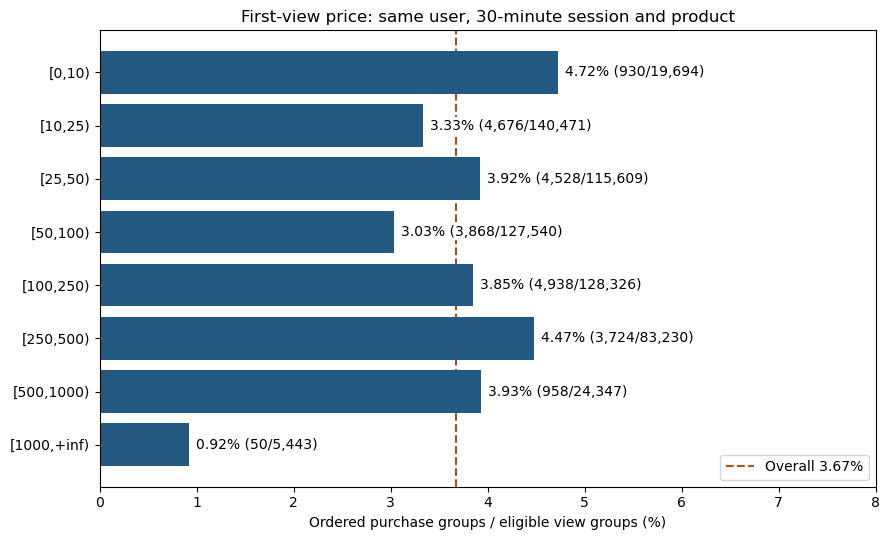

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(prices["price_band"], prices["ordered_purchase_pct"], color="#245a81")
labels = [f"{r.ordered_purchase_pct:.2f}% ({r.ordered_purchase_groups:,}/{r.eligible_groups:,})" for r in prices.itertuples()]
ax.bar_label(bars, labels=labels, padding=5, fontsize=10,
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(primary["ordered_purchase_pct"], color="#a75123", linestyle="--", zorder=0,
           label=f"Overall {primary['ordered_purchase_pct']:.2f}%")
ax.invert_yaxis()
ax.set_xlim(0, 8)
ax.set_xlabel("Ordered purchase groups / eligible view groups (%)")
ax.set_title("First-view price: same user, 30-minute session and product")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


### Read the stage differences

Of 644,660 eligible groups, 49,459 reached cart and 23,672 reached an ordered purchase. View-to-cart is 7.67%, full progression 3.67%, and cart-to-purchase 47.86%.

TVs have 596/17,065 cart groups and 228/596 subsequent purchases. Video cards have 11,698/72,098 and 4,712/11,698 respectively. These patterns do not establish a product-page or checkout cause.

The 1,000+ price band has 50/5,443 = 0.92% progression. Rates do not fall monotonically across the other bands. Product mix and observation differences remain possible explanations. The next section examines uncertainty and measurement sensitivity.


### A purchase outside the funnel is not a failed purchase

Some purchase groups lack a same-session product view or a strict observed sequence. The following tables separate those cases. A group can contain multiple purchase events. Groups without a complete session-close buffer are excluded rather than counted as nonconverters.


In [13]:
display(pd.read_csv(root / "reports/07_purchase_path_coverage.csv"))
display(pd.read_csv(root / "reports/07_exclusions.csv"))
display(pd.read_csv(root / "reports/07_anchor_tie_audit.csv"))


,path_status,purchase_containing_groups,purchase_events
0,eligible_ordered_path,23672,32639
1,no_observed_view_in_unit,1778,2273
2,no_strict_cart_after_first_view,1702,2408
3,no_strict_purchase_after_qualifying_cart,15,18
4,right_edge_session_excluded,2,5


,late_view_pairs,pairs_without_view,view_groups_in_open_sessions,session_product_groups_without_view,open_sessions
0,23273,529,39,2106,31


,cohort,eligible_groups,groups_with_multiple_view_records_at_anchor,groups_with_conflicting_anchor_attributes
0,pair_7d,532888,38,0
1,session_30,644660,162,0


### Close temporary tables and recheck the inputs

Only temporary tables from this connection are dropped. The original CSVs and saved model remain unchanged.


In [14]:
conn.execute("DROP TABLE diagnostic_view_groups")
conn.close()
assert file_hash(model) == before_model
assert all(file_hash(Path(path)) == sha for path, sha in before_raw.items())
print("All notebook checks passed. Raw sources and saved model are unchanged.")


All notebook checks passed. Raw sources and saved model are unchanged.


---

## Analysis section: Robustness


## Measurement sensitivity and uncertainty

I compare measurement definitions on matched populations and resample customer/product clusters. These are exploratory checks on segments selected earlier. They do not estimate company improvement or category/price effects. Hillstrom remains a separate experiment.


### Check the inputs

The model is read-only. Cluster-count files contain integer vectors without customer or product IDs. They are local analysis inputs under `data/work`, excluded from Git.


In [15]:
from pathlib import Path
import json, sqlite3, sys, os
import pandas as pd
import numpy as np
root = Path.cwd()
if not (root / "src/run_robustness.py").exists():
    root = root.parent
assert (root / "src/run_robustness.py").exists()
sys.path.insert(0, str(root / "src"))
from intake import file_hash
from bootstrap_robustness import compress_vectors, bootstrap_totals, contrast_values, interval
os.environ.setdefault("MPLCONFIGDIR", str(root / "data/work/mpl-cache"))
payload = json.loads((root / "reports/08_robustness_results.json").read_text())
saved_boot = json.loads((root / "reports/08_cluster_intervals.json").read_text())
assert file_hash(root / "reports/08_robustness_results.json") == saved_boot["input_results_sha256"]
model = root / "data/processed/project01.sqlite"
assert file_hash(model) == payload["model_sha256"]
assert all(file_hash(root / name) == sha for name, sha in payload["source_hashes"].items())
conn = sqlite3.connect(model.as_uri() + "?mode=ro", uri=True)
print("Verified source/model snapshot; model opened read-only.")


Verified source/model snapshot; model opened read-only.


### Compare one, three and seven days on the same denominator

Keep customer-product pairs with seven complete follow-up days. Every window still requires view < cart < purchase. The shorter-window counts are recalculated from the eligible event times, holding the population fixed.


In [16]:
matched = pd.read_sql_query("""
WITH windows(days) AS (VALUES(1),(3),(7))
SELECT w.days, COUNT(*) AS eligible_groups,
       SUM(m.cart_after_view_ts <= m.view_ts+w.days*86400) AS cart_groups,
       SUM(m.purchase_after_view_cart_ts <= m.view_ts+w.days*86400) AS purchase_groups
FROM mart_user_product m CROSS JOIN windows w
WHERE m.view_ts <= (SELECT observed_end FROM model_config)-7*86400
GROUP BY w.days ORDER BY w.days
""", conn)
matched["percent"] = 100 * matched["purchase_groups"] / matched["eligible_groups"]
assert matched["eligible_groups"].nunique() == 1
assert matched["purchase_groups"].is_monotonic_increasing
display(matched.round(4))
print("Share of 7-day qualifying purchases already qualifying in 1 day:",
      round(100 * matched.iloc[0]["purchase_groups"] / matched.iloc[-1]["purchase_groups"], 2), "%")


Share of 7-day qualifying purchases already qualifying in 1 day: 95.57 %


,days,eligible_groups,cart_groups,purchase_groups,percent
0,1,532888,41381,20305,3.8104
1,3,532888,42067,20854,3.9134
2,7,532888,42526,21246,3.9870


### Separate population changes from window changes

Using each window's own eligible cohort changes both follow-up opportunity and population composition. These counts are therefore distinct from the matched-denominator comparison above.


In [17]:
native = pd.read_sql_query("""
WITH windows(days) AS (VALUES(1),(3),(7))
SELECT w.days, COUNT(*) AS eligible_groups,
       SUM(m.purchase_after_view_cart_ts <= m.view_ts+w.days*86400) AS purchase_groups
FROM mart_user_product m CROSS JOIN windows w
WHERE m.view_ts <= (SELECT observed_end FROM model_config)-w.days*86400
GROUP BY w.days ORDER BY w.days
""", conn)
native["percent"] = 100 * native["purchase_groups"] / native["eligible_groups"]
display(native.round(4))


,days,eligible_groups,purchase_groups,percent
0,1,552814,21201,3.8351
1,3,546174,21498,3.9361
2,7,532888,21246,3.9870


### Compare 30- and 60-minute sessions from the same anchors

The saved SQL results keep the original 30-minute first-view anchors and look for subsequent behavior within 30- and 60-minute sessions. Anchors without a complete 60-minute close buffer are excluded from both. One purchase may satisfy several anchors, so added progressions are not extra orders.


In [18]:
scenarios = pd.read_csv(root / "reports/08_scenarios.csv")
fixed = scenarios.loc[(scenarios["target"] == "Overall") &
                      scenarios["scenario"].isin(["fixed_anchor_30", "fixed_anchor_60"])]
assert fixed["eligible_groups"].nunique() == 1
display(fixed[["scenario", "eligible_groups", "cart_groups", "purchase_groups", "ordered_purchase_pct"]].round(4))
print("Measurement gap in percentage points:", round(fixed.iloc[1]["ordered_purchase_pct"] - fixed.iloc[0]["ordered_purchase_pct"], 4))


Measurement gap in percentage points: 0.143


,scenario,eligible_groups,cart_groups,purchase_groups,ordered_purchase_pct
0,fixed_anchor_30,644602,49450,23671,3.6722
5,fixed_anchor_60,644602,50439,24593,3.8152


### Check exact-duplicate sensitivity

These saved results came from an independent Python pass over the full raw CSV. This cell reads the fingerprinted results rather than repeating that pass. Exact copies of the same timestamp/customer/product/action may change event counts without changing binary progression. That conclusion does not apply to every kind of duplicate.


In [19]:
mix = pd.DataFrame({"raw": payload["raw_sensitivity"]["event_mix"],
                    "canonical": payload["canonical_event_mix"]})
mix["extra_raw_rows"] = mix["raw"] - mix["canonical"]
display(mix)
assert payload["raw_sensitivity"]["all_raw_canonical_contracted_counts_equal_at_both_gaps"]
print("All contracted binary counts match raw/canonical at both 30 and 60 minutes.")


All contracted binary counts match raw/canonical at both 30 and 60 minutes.


,raw,canonical,extra_raw_rows
view,793748,793099,649
cart,54035,54032,3
purchase,37346,37343,3


### Resample customer clusters

A customer's sessions and products may be related. Resampling keeps that customer's eligible groups together and draws 406,842 clusters with replacement.

Each cluster is an integer vector of overall, TV and other group counts. Equal vectors are compressed with their frequencies; this preserves the cluster-bootstrap distribution. The next cell generates one actual cluster sample without retaining IDs.


In [20]:
user_meta = next(x for x in payload["private_cluster_vectors"] if x["cluster"] == "user_id")
assert file_hash(root / user_meta["path"]) == user_meta["sha256"]
users = np.loadtxt(root / user_meta["path"], delimiter=",", skiprows=1, dtype=np.int64)
patterns, frequencies = compress_vectors(users)
rng = np.random.default_rng(payload["plan"]["seed"])
weights = rng.multinomial(len(users), frequencies / len(users))
one_draw_totals = weights @ patterns
print("Customer clusters:", len(users), "Count patterns:", len(patterns))
print("One draw: all groups / ordered purchases =", one_draw_totals[:2])


Customer clusters: 406842 Count patterns: 2756
One draw: all groups / ordered purchases = [646434  23714]


### Run 2,000 customer-cluster resamples

Each estimate is total purchases divided by total eligible groups, not the mean of customer-level rates. TV and complement use the same resampling weights. The 2.5th and 97.5th percentiles form marginal 95% intervals; they do not provide simultaneous coverage for all comparisons.


In [21]:
user_boot, _ = bootstrap_totals(users, payload["plan"]["replicates"], payload["plan"]["seed"])
def summarize(vectors, draws, cluster):
    rows = []
    for i, target in enumerate(payload["plan"]["targets"]):
        point = contrast_values(vectors.sum(axis=0), i)
        samples = contrast_values(draws, i)
        ci = interval(samples[2])
        target_ci = interval(samples[0])
        assert ci["undefined_replicates"] == 0
        rows.append({"cluster": cluster, "target": target, "target_pct": point[0][0],
                     "target_low": target_ci["low"], "target_high": target_ci["high"],
                     "difference_pp": point[2][0], "difference_low": ci["low"], "difference_high": ci["high"]})
    return pd.DataFrame(rows)
user_summary = summarize(users, user_boot, "user_id")
display(user_summary.round(3))


,cluster,target,target_pct,target_low,target_high,difference_pp,difference_low,difference_high
0,user_id,TV,1.336,1.149,1.533,-2.399,-2.594,-2.191
1,user_id,Video cards,6.536,6.298,6.781,3.224,2.983,3.474
2,user_id,Unknown category,2.640,2.550,2.720,-1.435,-1.542,-1.331
3,user_id,Price 1000+,0.919,0.647,1.208,-2.777,-3.043,-2.483


### Repeat with product clusters

Products can appear across customers, so I also resample products. Customer and product clustering are separate one-way assumptions. Running both does not jointly correct their crossed dependence, time shocks or missing logs.


In [22]:
product_meta = next(x for x in payload["private_cluster_vectors"] if x["cluster"] == "product_id")
assert file_hash(root / product_meta["path"]) == product_meta["sha256"]
products = np.loadtxt(root / product_meta["path"], delimiter=",", skiprows=1, dtype=np.int64)
product_boot, _ = bootstrap_totals(products, payload["plan"]["replicates"], payload["plan"]["seed"])
product_summary = summarize(products, product_boot, "product_id")
display(product_summary.round(3))
combined = pd.concat([user_summary, product_summary], ignore_index=True)
for row in combined.itertuples():
    saved = next(x for x in saved_boot["results"] if x["cluster"] == row.cluster and x["target"] == row.target)
    np.testing.assert_allclose([row.difference_low, row.difference_high],
                               [saved["difference_pp_interval"]["low"], saved["difference_pp_interval"]["high"]])
print("Actual notebook resampling reproduces saved intervals.")


Actual notebook resampling reproduces saved intervals.


,cluster,target,target_pct,target_low,target_high,difference_pp,difference_low,difference_high
0,product_id,TV,1.336,0.854,1.748,-2.399,-2.927,-1.916
1,product_id,Video cards,6.536,5.667,7.454,3.224,2.353,4.152
2,product_id,Unknown category,2.640,2.381,2.910,-1.435,-1.793,-1.057
3,product_id,Price 1000+,0.919,0.551,1.302,-2.777,-3.196,-2.334


### Read the contrasts

Each point is a segment rate minus its complement, in percentage points. Lines are marginal 95% cluster-bootstrap intervals; zero means no rate difference. These intervals describe hypothetical repeated cluster sampling, not a causal price or category effect.


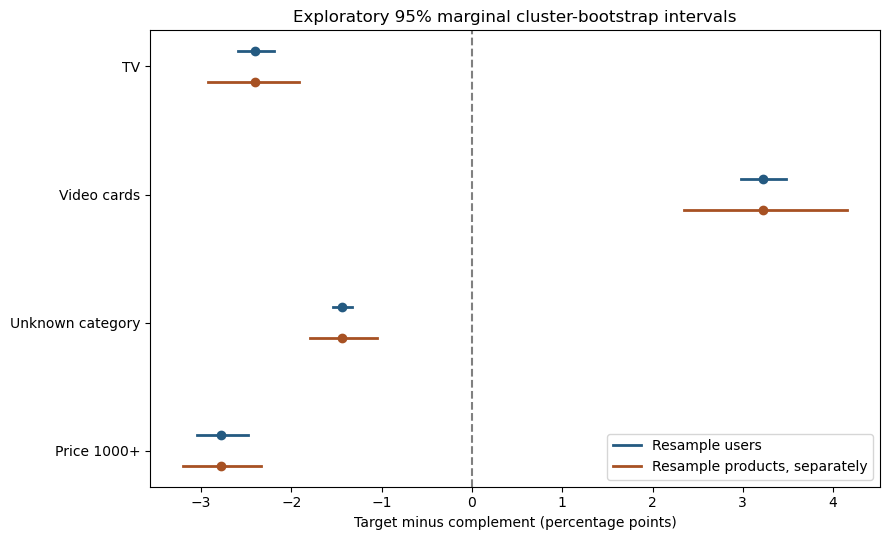

In [23]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 5.5))
for cluster, offset, color, label in [("user_id", -.12, "#245a81", "Resample users"),
                                     ("product_id", .12, "#a75123", "Resample products, separately")]:
    data = combined.loc[combined["cluster"] == cluster]
    for i, row in enumerate(data.itertuples()):
        y = i + offset
        ax.plot([row.difference_low, row.difference_high], [y, y], color=color, linewidth=2,
                label=label if i == 0 else None)
        ax.plot(row.difference_pp, y, "o", color=color)
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(range(4), payload["plan"]["targets"])
ax.invert_yaxis()
ax.set_xlabel("Target minus complement (percentage points)")
ax.set_title("Exploratory 95% marginal cluster-bootstrap intervals")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


### What survives the checks?

TV, Unknown and the 1,000+ price band remain below their complements in the examined scenarios; video cards remain above. Both one-way cluster analyses retain these directions.

The segments were selected after exploration. Crossed customer/product dependence, time effects, selection and logging gaps remain unresolved. I keep the primary metric definition fixed. The observed file rates are exact counts; the intervals depend on the stated resampling assumptions.


In [24]:
conn.close()
assert file_hash(model) == payload["model_sha256"]
assert all(file_hash(root / name) == sha for name, sha in payload["source_hashes"].items())
print("Notebook checks passed: SQL counts, actual cluster resampling, unchanged sources/model.")


Notebook checks passed: SQL counts, actual cluster resampling, unchanged sources/model.


Method references: [ClusterBootstrap](https://stat.ethz.ch/CRAN/web/packages/ClusterBootstrap/refman/ClusterBootstrap.html), [SciPy bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html), [NumPy multinomial](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.multinomial.html). The implementation below uses NumPy, not the cited R package or SciPy bootstrap function.


---

## Analysis section: Hillstrom Experiment


## Hillstrom randomized email experiment

This 2008 experiment is separate from REES46. Mens and Womens refer to merchandise content, not customer gender. The source describes random assignment and two-week outcomes. I estimate that historical assignment effect, not present-day performance or ROI.

The cells reread all assigned rows and recompute the summaries, statistical comparisons and 10,000 spend resamples.


### Inputs and analysis plan

Raw data: `data/raw/hillstrom/hillstrom.csv.gz`. Plan: `experiments/hillstrom/09_analysis_plan.json`. Statistics: `src/hillstrom_stats.py`.

The primary outcome is purchase-rate difference across all assigned customers. Visitors and buyers are not selected as a post-treatment subgroup. The two businesses' records are never joined.


In [25]:
from pathlib import Path
import json, sys, os
import pandas as pd
import numpy as np
root = Path.cwd()
if not (root / "experiments/hillstrom/analyze_hillstrom.py").exists():
    root = root.parent
assert (root / "experiments/hillstrom/analyze_hillstrom.py").exists()
sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root / "experiments/hillstrom"))
from intake import file_hash
from hillstrom_stats import compare_binary, holm, bootstrap_spend_means, percentile_interval
from analyze_hillstrom import load_rows, arm_summary, baseline_balance, ARMS
os.environ.setdefault("MPLCONFIGDIR", str(root / "data/work/mpl-cache"))
saved = json.loads((root / "reports/09_ab_results.json").read_text())
plan = json.loads((root / "experiments/hillstrom/09_analysis_plan.json").read_text())
for name, sha in saved["snapshots_unchanged"].items():
    assert file_hash(root / name) == sha
print("Frozen plan and source/model snapshot verified.")


Frozen plan and source/model snapshot verified.


### Retain all 64,000 assigned rows

The loader checks columns, missingness, binary outcomes, monetary amounts and outcome consistency. Source-row numbers are provenance, not customer IDs. Identical attributes do not prove duplicate customers, so those rows remain. Integer cents avoid rounding monetary totals.


In [26]:
rows = load_rows(root / "data/raw/hillstrom/hillstrom.csv.gz")
assert len(rows) == 64000
df = pd.DataFrame(rows)
print("Assigned customer rows retained:", len(df))
print("Original attributes plus source-row provenance and integer spend cents:", list(df.columns))


Assigned customer rows retained: 64000
Original attributes plus source-row provenance and integer spend cents: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend', 'source_row', 'spend_cents']


### Aggregate by assigned arm

`size` counts every assigned row; summing binary outcomes counts visitors and purchasers. Purchase rate and mean spend both use all assigned customers. Independent SQL and pandas integer totals must match.


In [27]:
summary = df.groupby("segment").agg(
    assigned_n=("source_row", "size"), purchasers=("conversion", "sum"),
    visitors=("visit", "sum"), spend_cents_total=("spend_cents", "sum")
).loc[ARMS]
summary["purchase_pct"] = 100 * summary["purchasers"] / summary["assigned_n"]
summary["visit_pct"] = 100 * summary["visitors"] / summary["assigned_n"]
summary["mean_spend_dollars"] = summary["spend_cents_total"] / (100 * summary["assigned_n"])
for item in arm_summary(rows):
    for column in ["assigned_n", "purchasers", "visitors", "spend_cents_total"]:
        assert summary.loc[item["segment"], column] == item[column]
display(summary.round(4))


,assigned_n,purchasers,visitors,spend_cents_total,purchase_pct,visit_pct,mean_spend_dollars
segment,,,,,,,
No E-Mail,21306,122,2262,1390833,0.5726,10.6167,0.6528
Mens E-Mail,21307,267,3894,3031169,1.2531,18.2757,1.4226
Womens E-Mail,21387,189,3238,2303811,0.8837,15.1400,1.0772


### Check allocation and pretreatment balance

I compare allocation with nominal equal thirds and examine recency, history, prior purchases and channels. Outcomes are excluded from baseline checks. Balance is a diagnostic; the original source description supplies the randomized-design evidence.


In [28]:
from scipy.stats import chisquare
allocation = chisquare(summary["assigned_n"].to_numpy())
balance = pd.DataFrame(baseline_balance(rows, plan["baseline_balance"]))
print("Nominal equal-thirds allocation chi-square / p:", allocation.statistic, allocation.pvalue)
print("Maximum absolute pre-treatment SMD:", balance["smd"].abs().max())
print("SMD display flags > 0.1:", balance["abs_smd_above_point1"].sum())
display(balance.assign(abs_smd=balance["smd"].abs()).sort_values("abs_smd", ascending=False).head(8).round(4))


Nominal equal-thirds allocation chi-square / p: 0.20253125000000002 0.9036929575604196
Maximum absolute pre-treatment SMD: 0.016359543173779502
SMD display flags > 0.1: 0


,treatment,feature,level,treatment_n,control_n,treatment_mean,control_mean,smd,abs_smd_above_point1,abs_smd
12,Mens E-Mail,history_segment,2) $100 - $200,21307,21306,0.2202,0.2270,-0.0164,False,0.0164
22,Mens E-Mail,history_segment,"7) $1,000 +",21307,21306,0.0218,0.0195,0.0158,False,0.0158
13,Womens E-Mail,history_segment,2) $100 - $200,21387,21306,0.2210,0.2270,-0.0143,False,0.0143
24,Mens E-Mail,zip_code,Rural,21307,21306,0.1522,0.1473,0.0137,False,0.0137
26,Mens E-Mail,zip_code,Surburban,21307,21306,0.4459,0.4518,-0.0117,False,0.0117
15,Womens E-Mail,history_segment,3) $200 - $350,21387,21306,0.1943,0.1898,0.0114,False,0.0114
34,Mens E-Mail,channel,Web,21307,21306,0.4454,0.4399,0.0110,False,0.0110
10,Mens E-Mail,history_segment,1) $0 - $100,21307,21306,0.3625,0.3573,0.0109,False,0.0109


### Estimate each email-versus-control purchase difference

The contrast is treatment purchasers/assigned minus control purchasers/assigned. Multiplying by 100 gives percentage points, not relative percentage lift. `compare_binary` returns marginal Newcombe-Wilson intervals and two-sided pooled-proportion z tests, checked against statsmodels.


In [29]:
control = summary.loc["No E-Mail"]
primary_rows = []
for arm in ARMS[1:]:
    treatment = summary.loc[arm]
    result = compare_binary(int(treatment["purchasers"]), int(treatment["assigned_n"]),
                            int(control["purchasers"]), int(control["assigned_n"]))
    primary_rows.append({"treatment": arm, **result})
primary = pd.DataFrame(primary_rows)
display(primary[["treatment", "treatment_successes", "treatment_n", "control_successes", "control_n",
                 "difference_pp", "relative_lift_pct", "ci_low_pp", "ci_high_pp", "p_raw"]])


,treatment,treatment_successes,treatment_n,control_successes,control_n,difference_pp,relative_lift_pct,ci_low_pp,ci_high_pp,p_raw
0,Mens E-Mail,267,21307,122,21306,0.680501,118.842188,0.501434,0.864072,1.523224e-13
1,Womens E-Mail,189,21387,122,21306,0.311106,54.331304,0.150166,0.474547,1.571051e-04


### Apply Holm correction to the two primary tests

The two treatment-control purchase comparisons form the prespecified family at alpha 0.05. Holm-adjusted p-values return to the original contrast order. Visit, spend and direct campaign comparisons remain exploratory. Displayed 95% intervals are marginal, not Holm-adjusted simultaneous intervals.


In [30]:
primary["p_holm"] = holm(primary["p_raw"].tolist())
primary["reject_holm_005"] = primary["p_holm"] <= 0.05
assert len(primary) == 2
for item in saved["profiles"]["binary_effects"]:
    if item["metric"] == "purchase":
        actual = primary.loc[primary["treatment"] == item["treatment"]].iloc[0]
        np.testing.assert_allclose(actual["p_holm"], item["p_holm"], rtol=1e-12)
display(primary[["treatment", "difference_pp", "ci_low_pp", "ci_high_pp", "p_raw", "p_holm", "reject_holm_005"]])


,treatment,difference_pp,ci_low_pp,ci_high_pp,p_raw,p_holm,reject_holm_005
0,Mens E-Mail,0.680501,0.501434,0.864072,1.523224e-13,3.046447e-13,True
1,Womens E-Mail,0.311106,0.150166,0.474547,1.571051e-04,1.571051e-04,True


### Plot purchase effects

Points are purchase-probability differences versus control; lines are marginal 95% intervals. Zero marks no difference. The interval interpretation is separate from the Holm test decision.


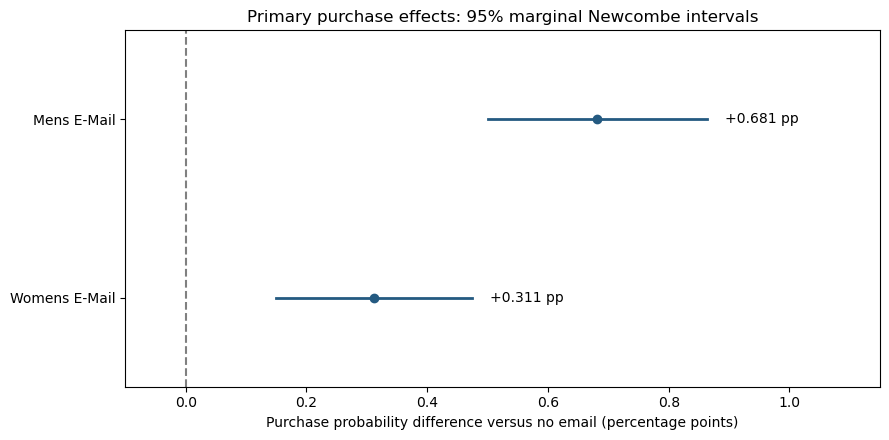

In [31]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, row in enumerate(primary.itertuples()):
    ax.plot([row.ci_low_pp, row.ci_high_pp], [i, i], color="#245a81", linewidth=2)
    ax.plot(row.difference_pp, i, "o", color="#245a81")
    ax.text(row.ci_high_pp + .03, i, f"{row.difference_pp:+.3f} pp", va="center")
ax.set_yticks(range(2), primary["treatment"])
ax.set_ylim(1.5, -.5)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlim(-.1, 1.15)
ax.set_xlabel("Purchase probability difference versus no email (percentage points)")
ax.set_title("Primary purchase effects: 95% marginal Newcombe intervals")
fig.tight_layout()
plt.show()


### Explore visit differences

Visit rates also use all assigned customers. Conditioning on visitors would select customers using behavior affected by email assignment. Visit and spend analyses are secondary.


In [32]:
visit_rows = []
for arm in ARMS[1:]:
    treatment = summary.loc[arm]
    visit_rows.append({"treatment": arm, **compare_binary(int(treatment["visitors"]), int(treatment["assigned_n"]),
                                                        int(control["visitors"]), int(control["assigned_n"]))})
visit = pd.DataFrame(visit_rows)
display(visit[["treatment", "difference_pp", "ci_low_pp", "ci_high_pp"]].round(4))


,treatment,difference_pp,ci_low_pp,ci_high_pp
0,Mens E-Mail,7.6590,6.9953,8.3227
1,Womens E-Mail,4.5233,3.8894,5.1574


### Resample mean spend, including zero spend

Each arm is resampled with replacement at its original size, 10,000 times, seed 1729. Equal spend amounts are frequency-compressed, including every zero. Around 98-99% of customers spent zero. Removing them would change the estimand. Both contrasts share the same control draws.


In [33]:
cents = {arm: df.loc[df["segment"] == arm, "spend_cents"].to_numpy(dtype=np.int64) for arm in ARMS}
for arm in ARMS:
    print(arm, "assigned:", len(cents[arm]), "zero spend:", np.count_nonzero(cents[arm] == 0))
means = bootstrap_spend_means(cents, plan["spend_bootstrap"]["replicates"], plan["spend_bootstrap"]["seed"])
spend_rows = []
for arm in ARMS[1:]:
    difference_draws = means[arm] - means["No E-Mail"]
    low, high = percentile_interval(difference_draws)
    spend_rows.append({"treatment": arm, "mean_difference_dollars": summary.loc[arm, "mean_spend_dollars"] - control["mean_spend_dollars"],
                       "ci_low": low, "ci_high": high})
    expected = next(x for x in saved["profiles"]["spend_effects"] if x["treatment"] == arm)
    np.testing.assert_allclose([low, high], [expected["ci_low_dollars"], expected["ci_high_dollars"]], rtol=1e-12)
spend = pd.DataFrame(spend_rows)
display(spend.round(4))


No E-Mail assigned: 21306 zero spend: 21184
Mens E-Mail assigned: 21307 zero spend: 21040
Womens E-Mail assigned: 21387 zero spend: 21198


,treatment,mean_difference_dollars,ci_low,ci_high
0,Mens E-Mail,0.7698,0.4976,1.0566
1,Womens E-Mail,0.4244,0.1703,0.6828


### Plot recorded-spend differences

Amounts are historical nominal dollars. They are not a profit calculation with taxes, refunds, margins and campaign costs. Percentile intervals are exploratory and separate from the primary purchase-test family.


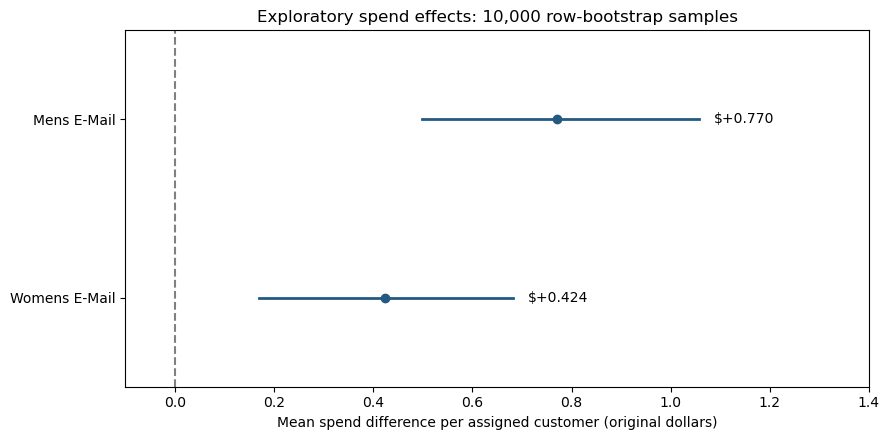

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, row in enumerate(spend.itertuples()):
    ax.plot([row.ci_low, row.ci_high], [i, i], color="#245a81", linewidth=2)
    ax.plot(row.mean_difference_dollars, i, "o", color="#245a81")
    ax.text(row.ci_high + .03, i, f"${row.mean_difference_dollars:+.3f}", va="center")
ax.set_yticks(range(2), spend["treatment"])
ax.set_ylim(1.5, -.5)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlim(-.1, 1.4)
ax.set_xlabel("Mean spend difference per assigned customer (original dollars)")
ax.set_title("Exploratory spend effects: 10,000 row-bootstrap samples")
fig.tight_layout()
plt.show()


### Compare the campaigns directly

Separate treatment-control tests do not test the difference between the two emails. The Mens-minus-Womens contrast below is exploratory and outside the two-test Holm family.


In [35]:
mens, womens = summary.loc["Mens E-Mail"], summary.loc["Womens E-Mail"]
direct = compare_binary(int(mens["purchasers"]), int(mens["assigned_n"]),
                        int(womens["purchasers"]), int(womens["assigned_n"]))
print("Exploratory Mens minus Womens purchase pp / interval:",
      direct["difference_pp"], direct["ci_low_pp"], direct["ci_high_pp"])
print("Exploratory mean spend difference / interval:",
      mens["mean_spend_dollars"] - womens["mean_spend_dollars"],
      percentile_interval(means["Mens E-Mail"] - means["Womens E-Mail"]))


Exploratory Mens minus Womens purchase pp / interval: 0.3693949008530437 0.1746284814190172 0.5662614423391559
Exploratory mean spend difference / interval: 0.3454149399579398 [0.0392083705258776, 0.6600340208155445]


### Reconcile calculations and preserve inputs

Newcombe intervals, z-test p-values and Holm results are checked against statsmodels. SQL and pandas integer totals agree. Every assigned row remains, and the source/model hashes are rechecked.


In [36]:
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest
from statsmodels.stats.multitest import multipletests
for row in primary.itertuples():
    ci = confint_proportions_2indep(row.treatment_successes, row.treatment_n,
                                   row.control_successes, row.control_n, method="newcomb", compare="diff")
    np.testing.assert_allclose([row.ci_low_pp, row.ci_high_pp], 100 * np.array(ci), rtol=1e-10)
    library_p = proportions_ztest([row.treatment_successes, row.control_successes], [row.treatment_n, row.control_n])[1]
    np.testing.assert_allclose(row.p_raw, library_p, rtol=1e-10)
np.testing.assert_allclose(primary["p_holm"], multipletests(primary["p_raw"], method="holm")[1], rtol=1e-10)
for name, sha in saved["snapshots_unchanged"].items():
    assert file_hash(root / name) == sha
print("Notebook checks passed: all rows retained, exact aggregates, statistics/bootstrap reproduced, sources/model unchanged.")


Notebook checks passed: all rows retained, exact aggregates, statistics/bootstrap reproduced, sources/model unchanged.


### Decision

Both email assignments increased historical purchase rates versus control and passed the primary Holm policy. Mens has the larger purchase estimate; the exploratory direct comparison points the same way.

Current deployment needs a contemporary experiment and cost/margin data. Receipt, open and cost fields are absent. I do not claim an optimal 10,000-customer audience or ROI. Power BI keeps this case separate from REES46.

Sources: [Hillstrom](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html), [TensorFlow catalog](https://www.tensorflow.org/datasets/catalog/hillstrom), [Newcombe intervals](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.confint_proportions_2indep.html), [Holm](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).
